In [1]:
!pip3 install scanpy==1.9.3

In [2]:
!pip3 install scib-metrics==0.5.1 #bug in version from requirements

In [3]:
!pip3 install leidenalg==0.10.1

In [4]:
!pip3 install louvain==0.8.1

## Imports

In [5]:
import scanpy as sc
import numpy as np
import pandas as pd
import metrics_lib as metrics
import os

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2024-03-26 16:55:48.645313: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9373] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-26 16:55:48.645395: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-26 16:55:48.648765: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1534] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Set global variables

In [6]:
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Data'))
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results'))

In [7]:
#set variables to subset data
dataset="Sheppard_2020"
condition="IPF"
mode="dataset"

## load and prep Data

### load and prep embedding 

In [8]:
adata = sc.read_h5ad(f"{DATA_DIR}/Mapping/sheppard_dataset.h5ad")

In [9]:
# make X to obsm
adata.obsm["X_scanvi"] = adata.X

In [10]:
#subset to dataset
adata=adata[(adata.obs.dataset == dataset )|(adata.obs['core_or_extension']=="core") ].copy()

In [11]:
adata.obs.loc[~(adata.obs.dataset == dataset), "condition"]="NML"

In [12]:
#subset to condition
adata=adata[(adata.obs.condition == condition )|(adata.obs['core_or_extension']=="core") ].copy()


### load and prep query_counts

In [13]:
adata_query=sc.read_h5ad(f"{DATA_DIR}/Query_counts/subsetted_HLCA.h5ad")

In [14]:
del adata_query.obsm["X_scanvi_emb"] #not the one we are working with

In [15]:
adata_query

AnnData object with n_obs × n_vars = 209101 × 56295
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', '

In [16]:
#set obs

In [17]:
adata[adata.obs.core_or_extension=="extension"].obs.index

Index(['TGAGCATGTTGCCTCT_IPF3', 'AACCATGGTGGTCCGT_IPF3',
       'TGCCAAATCTCAAACG_IPF2', 'CGTGTAATCTACTCAT_IPF3',
       'CGTAGCGAGACTTTCG_IPF3', 'CATGCCTCACATGTGT_IPF2',
       'ATCATCTGTACCGTAT_IPF3', 'AACTGGTTCTGTTTGT_IPF3',
       'ACGGGCTCATCCGGGT_IPF3', 'CCTCTGAGTCTGCCAG_IPF1',
       ...
       'GCCTCTACAACGCACC_IPF3', 'GTTCATTGTCTGCAAT_IPF3',
       'CATATGGTCTGCCAGG_IPF2', 'GTATCTTCACCCAGTG_IPF3',
       'GGGACCTGTAATTGGA_IPF3', 'TGCACCTTCGTACCGG_IPF2',
       'CTGATCCGTTAAGGGC_IPF3', 'AGCAGCCAGTACGCCC_IPF3',
       'TCAGCTCTCTAGCACA_IPF3', 'GTCATTTTCTTAGAGC_IPF3'],
      dtype='object', length=33817)

In [18]:
#new index (remove tsukui to synchronize data)
adata_query.obs.index= [i.strip("_tsukui") for i in adata_query.obs.index]

In [19]:
#subset to only query of interest (dataset and condition)
adata_query =  adata_query[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [20]:
adata_query.obs = adata.obs.loc[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [21]:
adata_query.obsm["X_scanvi"] = adata[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))].X

## run metrics

In [22]:
#set some variables for running metrics
obsm_emb_key = 'X_scanvi'
donor_key= 'donor_id'
dataset_key="dataset"
sample_key="sample"
original_emb_key=None
batch_key = "dataset"

In [23]:
scib_results = metrics.calculate_scib_metrics(adata, obsm_emb_key, batch_key, dataset_key, sample_key, dry_run=False)

Time to complete scib neighbors calculation: 606.515 s
Time to complete lisi_batch: 7.658 s
Time to complete kbet_batch: 1.948 s


In [24]:
symphony_results = metrics.calculate_symphony_metrics(adata, adata_query, obsm_emb_key, donor_key, dataset_key, sample_key, dry_run=False)

Time to complete symphony metrics neighbors calculation: 5.931 s
Time to complete lisi_query_donor: 1.140 s
Time to complete wiq_knn_corr: 206.931 s


In [25]:
other_results = metrics.calculate_other_metrics(adata, adata_query, obsm_emb_key, dataset_key, sample_key, dry_run=False)

/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell


Time to complete cluster_preservation_score: 119.104 s


In [26]:
#save results
adata.obs["lisi_batch"] = scib_results["lisi_batch"]["per_cell"]
adata.obs["kbet_batch"] = scib_results["kbet_batch"]["per_cell"]
adata.obs['lisi_query_donor'] = symphony_results['lisi_query_donor']["per_cell"]
adata.obs['wiq_knn_corr'] = symphony_results['wiq_knn_corr']["per_cell"]
adata.obs['cluster_preservation_score']=other_results['cluster_preservation_score']["per_cell"]

In [27]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].dropna()

,lisi_batch,kbet_batch,lisi_query_donor,wiq_knn_corr,cluster_preservation_score
TGAGCATGTTGCCTCT_IPF3,-1.702990e-08,0.0,0.000000e+00,0.289568,5.000000
AACCATGGTGGTCCGT_IPF3,0.000000e+00,0.0,7.050467e-12,0.239936,0.948457
TGCCAAATCTCAAACG_IPF2,1.771024e-03,0.0,0.000000e+00,0.288079,0.000000
CGTGTAATCTACTCAT_IPF3,0.000000e+00,0.0,-7.050467e-12,0.229118,5.000000
CGTAGCGAGACTTTCG_IPF3,0.000000e+00,0.0,7.050467e-12,0.222461,5.000000
...,...,...,...,...,...
TGCACCTTCGTACCGG_IPF2,4.722857e-02,0.0,1.057570e-11,0.404818,5.000000
CTGATCCGTTAAGGGC_IPF3,8.514949e-09,0.0,0.000000e+00,0.067283,5.000000
AGCAGCCAGTACGCCC_IPF3,-3.405980e-08,0.0,-1.410093e-11,0.118452,2.332678
TCAGCTCTCTAGCACA_IPF3,-1.702990e-08,0.0,3.525233e-12,0.005624,0.000000


In [28]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].to_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv')

## Visualize 

Run Load and prep embeddings and set global variables first

In [29]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']] = pd.read_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv',index_col = "Unnamed: 0")

In [30]:
sc.pp.neighbors(adata,n_neighbors=50)

In [31]:
sc.tl.umap(adata)

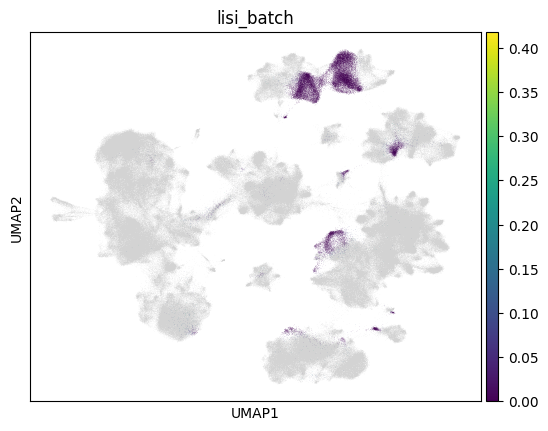

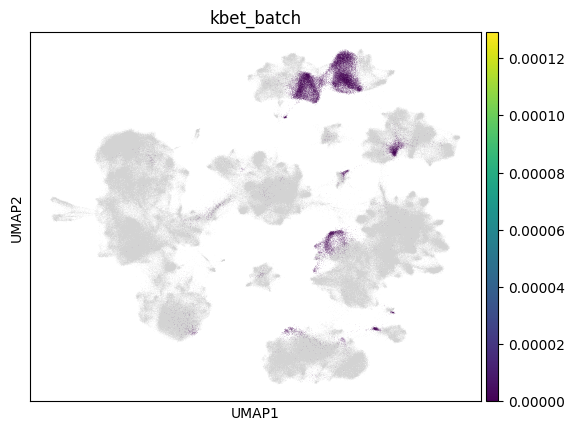

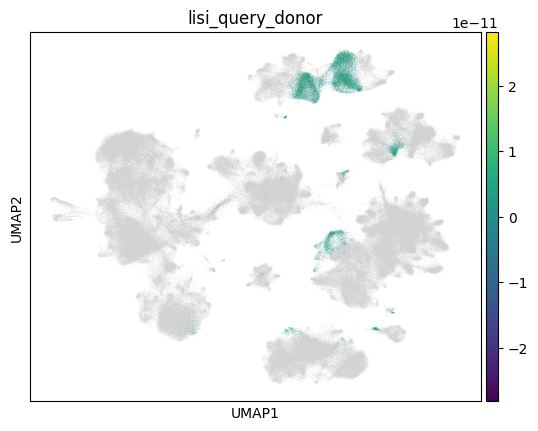

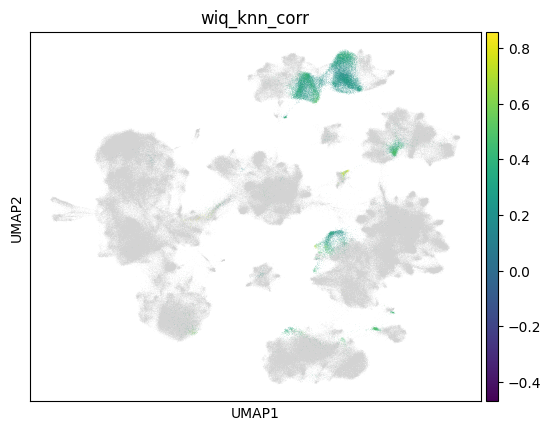

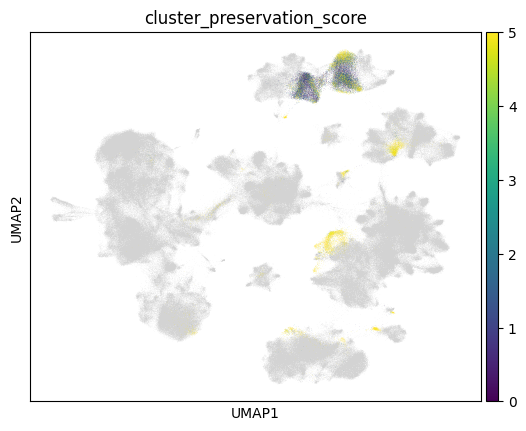

In [32]:
for metric in ["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']:
    adata.obs.loc[adata.obs.core_or_extension=="core",metric]=np.nan
    sc.pl.umap(adata,color=metric)